In this notebook the hits from background sources are analysed. The goals are to:
1. Analyse detector activation of each background source
2. Compare hit-based metrics across background sources.

## 0 - Introduction

This section contains imports, commons settings, constant value definition and declaration of some usuful funcion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import plotly.graph_objects as go

In [2]:
# To properly visualization
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

# To reset the options to their default values uncomment the following lines and run the cell
# pd.reset_option("display.max_rows")
# pd.reset_option("display.max_columns")
# pd.reset_option("display.max_colwidth")
# pd.reset_option("display.width")

In [3]:
url_ds = "../../data/Engineered_Datasets/bg_tgf_full.csv"
ds = pd.read_csv(url_ds, header=0)

DIM_CUBE = 10

cols = [
    'event_index', 
    'pixel_ijk', 
    'primary_e0_kev',
    #'n_voxels', 
    # 'E_sum', 
    # 'E_mean', 
    # 'E_std', 
    # 'E_min', 
    # 'E_max', 
    # 'E_median', 
    # 'E_p10', 
    # 'E_p25', 
    # 'E_p75', 
    # 'E_p90', 
    # 'E_p95', 
    # 'E_p99', 
    # 'E_iqr', 
    # 'E_mad', 
    # 'E_skew', 
    # 'E_kurt', 
    # 'entropy', 
    # 'gini', 
    'n_active', 
    # 'frac_active', 
    # 'frac_top1', 
    # 'frac_top3', 
    # 'eff_E_ge_T', 
    # 'com_x', 
    # 'com_y', 
    # 'com_z', 
    # 'rg', 
    # 'lam1', 
    # 'lam2', 
    # 'lam3', 
    # 'linearity', 
    # 'planarity', 
    # 'sphericity', 
    # 'asym_x', 
    # 'asym_y', 
    # 'asym_z', 
    # 'span_x', 
    # 'span_y', 
    # 'span_z', 
    'hits_sum', 
    'hits_mean_active', 
    # 'corr_E_hits', 
    # 'D_f', 
    # 'D_f_r2', 
    # 'f_occ', 
    # 'L_max_hops', 
    # 'L_max_metric', 
    # 'N_b', 
    # 'L_skel'
]

Define some function:

In [4]:
def pixel_conversion(pixel_ijk):
    """
    Convert pixel_ijk string to a list of tuples (i, j, k).
    Pixels are in format "[i, j , k];[i, j, k];...;[i, j, k]"
    """
    pixels_no_brackets = pixel_ijk.replace("[", "").replace("]", "")
    pixel_coord = pixels_no_brackets.split(",")

    i, j, k = map(int, pixel_coord)
    return i, j, k
    
# ### Test
# print("Test pixel conversion:")
# p1 = "[1, 2, 3]"
# i, j, k = pixel_conversion(p1)
# print(f"Input: {p1} -> Output: i={i}, j={j}, k={k}")

In [5]:
def create_detection_cube(hits_matrix, gap=0.02, colorscale="Plasma", opacity=0.9, min_hitted=0, show_arrows=True):
    """
    Create a 3D visualization of the detector activation with proportional 3D Cartesian arrow axes.

    Parameters:
        hits_matrix: A 3D numpy array representing the total hits in each sub-cube of the detector.
        gap: Spacing between sub-cubes.
        colorscale: Plotly colorscale for the voxels.
        opacity: Opacity of the voxel meshes.
        min_hitted: Minimum threshold for hits to be displayed.
        show_arrows: If True, draws 3D arrow axes (I, J, K) starting from the origin.
    """
    values = np.asarray(hits_matrix)
    nx, ny, nz = values.shape
    size = 1.0 - gap

    # Vertex and face definitions for a unit cube
    base_v = np.array([
        [0, 0, 0], [size, 0, 0], [size, size, 0], [0, size, 0],
        [0, 0, size], [size, 0, size], [size, size, size], [0, size, size]
    ])
    base_triangles = np.array([
        [7, 3, 0], [0, 4, 7], [0, 1, 2], [0, 2, 3],
        [4, 5, 6], [4, 6, 7], [6, 5, 1], [6, 1, 2],
        [4, 0, 1], [4, 1, 5], [3, 2, 6], [3, 6, 7]
    ])
    edge_seq = [0, 1, 2, 3, 0, 4, 5, 6, 7, 4, None, 1, 5, None, 2, 6, None, 3, 7]

    all_vx, all_vy, all_vz = [], [], []
    all_i, all_j, all_k = [], [], []
    intensity_list = []
    edge_x, edge_y, edge_z = [], [], []

    # Takes only coordinates with hits strictly greater than min_hitted
    active_coords = np.argwhere(values > min_hitted)

    if len(active_coords) == 0:
        print("Attenzione: nessun voxel con hit >", min_hitted)
        return go.Figure()

    vert_offset = 0
    for x, y, z in active_coords:
        val = values[x, y, z]
        cube_v = base_v + np.array([x, y, z])

        all_vx.extend(cube_v[:, 0])
        all_vy.extend(cube_v[:, 1])
        all_vz.extend(cube_v[:, 2])

        intensity_list.extend([val] * 8)

        shifted_tri = base_triangles + vert_offset
        all_i.extend(shifted_tri[:, 0])
        all_j.extend(shifted_tri[:, 1])
        all_k.extend(shifted_tri[:, 2])
        vert_offset += 8

        # Black edges for each cube
        for idx in edge_seq:
            if idx is None:
                edge_x.append(None); edge_y.append(None); edge_z.append(None)
            else:
                edge_x.append(cube_v[idx, 0])
                edge_y.append(cube_v[idx, 1])
                edge_z.append(cube_v[idx, 2])
        edge_x.append(None); edge_y.append(None); edge_z.append(None)

    # 1. Mesh of active voxels
    mesh = go.Mesh3d(
        x=all_vx, y=all_vy, z=all_vz,
        i=all_i, j=all_j, k=all_k,
        intensity=intensity_list,
        intensitymode='vertex',
        colorscale=colorscale,
        cmin=float(np.min(values[values > min_hitted])),
        cmax=float(np.max(values)),
        opacity=opacity,
        flatshading=True,
        colorbar=dict(title="Hits"),
        name="Hits"
    )

    # 2. Voxel outlines
    edges = go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode='lines',
        line=dict(color='black', width=1.5),
        hoverinfo='none',
        showlegend=False
    )

    # 3. Detector bounding box
    bbox_x = [0, nx, nx, 0, 0, 0, nx, nx, 0, 0, None, nx, nx, None, nx, nx, None, 0, 0]
    bbox_y = [0, 0, ny, ny, 0, 0, 0, ny, ny, 0, None, 0, 0, None, ny, ny, None, ny, ny]
    bbox_z = [0, 0, 0, 0, 0, nz, nz, nz, nz, nz, None, 0, nz, None, 0, nz, None, 0, nz]
    
    bounding_box = go.Scatter3d(
        x=bbox_x, y=bbox_y, z=bbox_z,
        mode='lines',
        line=dict(color='gray', width=2, dash='dot'),
        hoverinfo='none',
        showlegend=False
    )

    data = [mesh, edges, bounding_box]

    # 4. Proportional Cartesian Arrow Axes
    if show_arrows:
        max_d = max(nx, ny, nz)
        axis_len = max_d * 1.15
        head_len = max_d * 0.12

        axes_cfg = [
            ('I', 'red',   [0, axis_len, 0, 0, 0, 0], [head_len, 0, 0], [axis_len * 1.12, 0, 0]),
            ('J', 'green', [0, 0, 0, axis_len, 0, 0], [0, head_len, 0], [0, axis_len * 1.12, 0]),
            ('K', 'blue',  [0, 0, 0, 0, 0, axis_len], [0, 0, head_len], [0, 0, axis_len * 1.12])
        ]

        for name, color, coords, vec, label_p in axes_cfg:
            # Shaft line
            data.append(go.Scatter3d(
                x=[coords[0], coords[1]],
                y=[coords[2], coords[3]],
                z=[coords[4], coords[5]],
                mode='lines',
                line=dict(color=color, width=5),
                hoverinfo='none',
                showlegend=False
            ))

            # Arrowhead cone
            data.append(go.Cone(
                x=[coords[1]], y=[coords[3]], z=[coords[5]],
                u=[vec[0]], v=[vec[1]], w=[vec[2]],
                anchor='tail',
                sizemode='scaled',
                sizeref=1.0,
                colorscale=[[0, color], [1, color]],
                showscale=False,
                hoverinfo='none'
            ))

            # Axis label
            data.append(go.Scatter3d(
                x=[label_p[0]], y=[label_p[1]], z=[label_p[2]],
                mode='text',
                text=[f'<b>{name}</b>'],
                textfont=dict(color=color, size=15),
                hoverinfo='none',
                showlegend=False
            ))

    fig = go.Figure(data=data)
    
    max_range = max(nx, ny, nz) * 1.25
    max_range = max(nx, ny, nz) * 1.25
    fig.update_layout(
        scene=dict(
            aspectmode='data',
            xaxis=dict(
                title='I (pixel)', 
                range=[-0.5, max_range],
                showbackground=False,  
                showgrid=False,        
                showline=False,       
                zeroline=False
            ),
            yaxis=dict(
                title='J (pixel)', 
                range=[-0.5, max_range],
                showbackground=False,
                showgrid=False,
                showline=False,
                zeroline=False
            ),
            zaxis=dict(
                title='K (pixel)', 
                range=[-0.5, max_range],
                showbackground=False,
                showgrid=False,
                showline=False,
                zeroline=False
            )
        ),
        paper_bgcolor='white',  
        margin=dict(l=0, r=0, b=0, t=30)
    )
    return fig

In [6]:
def plot_detector_layes(hits_matrix, colorscale="plasma", min_hitted=0):
    """
        Create a 2D visualization of the dector activation by plotting each layer of the 3D hits matrix as a separate subplot as heatmap.
        The view is along x-axis, so each subplot represents a slice of the detector along the x-axis.
    """
    n_layers = hits_matrix.shape[0]
    ncols = 5
    nrows = int(np.ceil(n_layers / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows))
    axes = np.atleast_1d(axes).flatten()

    for i in range(n_layers):
        # .T make the X axis correspond to J and the Y axis to K
        sns.heatmap(
            hits_matrix[i, :, :].T, 
            ax=axes[i], 
            cmap=colorscale, 
            cbar=True, 
            square=True, 
            annot=True, 
            fmt=".0f", 
            linewidths=0.5, 
            linecolor='black', 
            vmin=min_hitted
        )

        axes[i].invert_yaxis()

        axes[i].set_title(f'I = {i} (layer {i+1}/{n_layers})')
        axes[i].set_xlabel('J (pixel)')
        axes[i].set_ylabel('K (pixel)')

    # Turn off any unused subplots
    for j in range(n_layers, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

# # Test
# sample_hits_matrix = np.random.randint(0, 100, size=(4, 4, 4))
# plot_detector_layes(sample_hits_matrix, min_hitted=0)

# 1 - Detector Activation

## 1.1 - Albedo Photons

In [7]:
albedo = ds[ds["particle_type"] == "AlbedoPhotons"]
print("Albedo Photons dataset shape:", albedo.shape)

albedo = albedo[cols]
print("Albedo Photons dataset shape after selecting columns:", albedo.shape)
print("Selected columns:", albedo.columns.tolist())

Albedo Photons dataset shape: (86862, 54)
Albedo Photons dataset shape after selecting columns: (86862, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [8]:
if "hits_sum" in albedo.columns and "n_active" in albedo.columns:
    discrepancies = albedo[albedo["n_active"] != albedo["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        albedo = albedo.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in albedo.columns and "n_active" in albedo.columns:
    for i in range(albedo.shape[0]):
        pixel_ijk = albedo.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = albedo.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [9]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in albedo["pixel_ijk"]: 
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

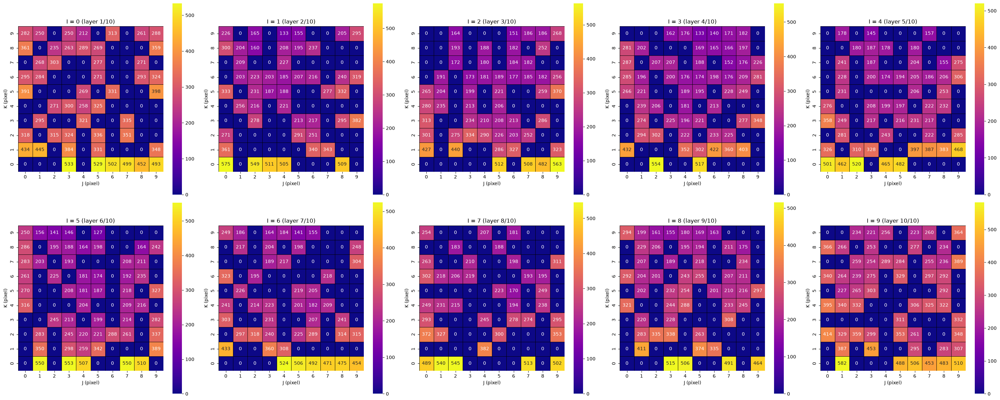

In [10]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.2 - Atmospheric Neutrons

In [11]:
atm_neutrons = ds[ds["particle_type"] == "AtmosphericNeutrons"]

print("Atmospheric Neutrons dataset shape:", atm_neutrons.shape)

atm_neutrons = atm_neutrons[cols]
print("Atmospheric Neutrons dataset shape after selecting columns:", atm_neutrons.shape)
print("Selected columns:", atm_neutrons.columns.tolist())

Atmospheric Neutrons dataset shape: (9962, 54)
Atmospheric Neutrons dataset shape after selecting columns: (9962, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [12]:
if "hits_sum" in atm_neutrons.columns and "n_active" in atm_neutrons.columns:
    discrepancies = atm_neutrons[atm_neutrons["n_active"] != atm_neutrons["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        atm_neutrons = atm_neutrons.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in atm_neutrons.columns and "n_active" in atm_neutrons.columns:
    for i in range(atm_neutrons.shape[0]):
        pixel_ijk = atm_neutrons.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = atm_neutrons.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [13]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in atm_neutrons["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

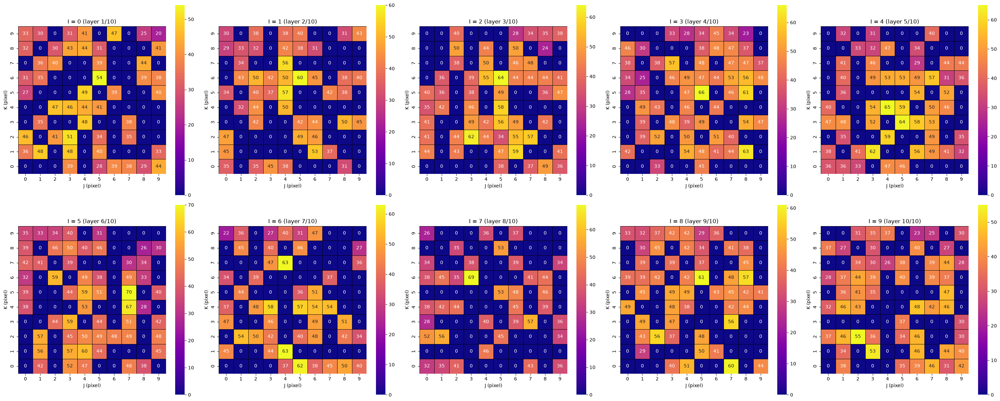

In [14]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.3 - Cosmic Photons

In [15]:
cosmic_pht = ds[ds["particle_type"] == "CosmicPhotons"]

print("Cosmic Photons dataset shape:", cosmic_pht.shape)

cosmic_pht = cosmic_pht[cols]
print("Cosmic Photons dataset shape after selecting columns:", cosmic_pht.shape)
print("Selected columns:", cosmic_pht.columns.tolist())

Cosmic Photons dataset shape: (152860, 54)
Cosmic Photons dataset shape after selecting columns: (152860, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [16]:
if "hits_sum" in cosmic_pht.columns and "n_active" in cosmic_pht.columns:
    discrepancies = cosmic_pht[cosmic_pht["n_active"] != cosmic_pht["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        cosmic_pht = cosmic_pht.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in cosmic_pht.columns and "n_active" in cosmic_pht.columns:
    for i in range(cosmic_pht.shape[0]):
        pixel_ijk = cosmic_pht.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = cosmic_pht.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [17]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in cosmic_pht["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

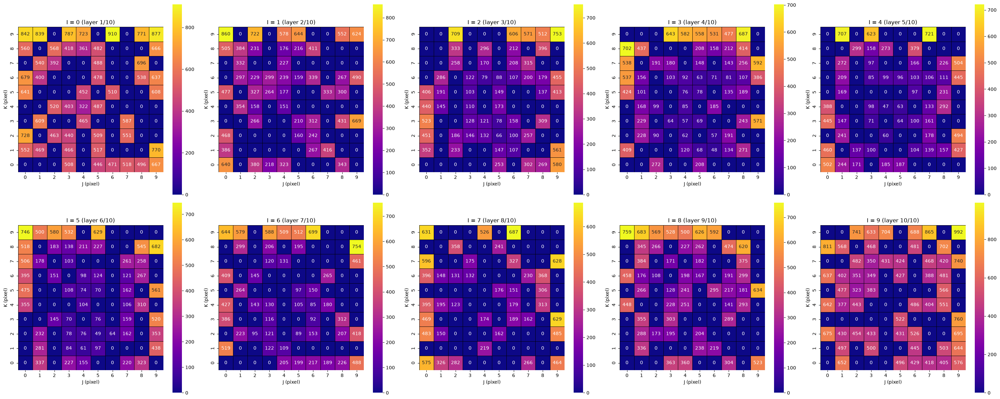

In [18]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.4 - Primary Alphas

In [19]:
prim_alphas = ds[ds["particle_type"] == "PrimaryAlphas"]

print("Primary Alphas dataset shape:", prim_alphas.shape)

prim_alphas = prim_alphas[cols]
print("Primary Alphas dataset shape after selecting columns:", prim_alphas.shape)
print("Selected columns:", prim_alphas.columns.tolist())

Primary Alphas dataset shape: (11677, 54)
Primary Alphas dataset shape after selecting columns: (11677, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [20]:
if "hits_sum" in prim_alphas.columns and "n_active" in prim_alphas.columns:
    discrepancies = prim_alphas[prim_alphas["n_active"] != prim_alphas["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        prim_alphas = prim_alphas.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in prim_alphas.columns and "n_active" in prim_alphas.columns:
    for i in range(prim_alphas.shape[0]):
        pixel_ijk = prim_alphas.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = prim_alphas.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [21]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in prim_alphas["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

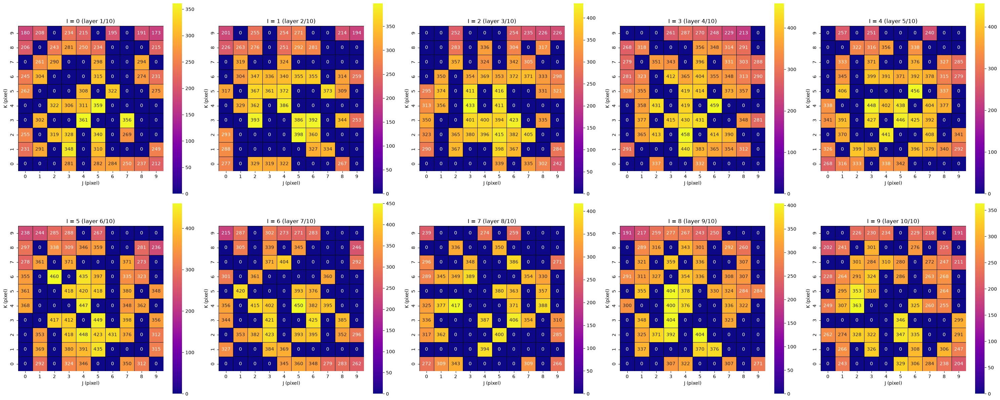

In [22]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.5 - Primary Electrons

In [23]:
prim_electrons = ds[ds["particle_type"] == "PrimaryElectrons"]
print("Primary Electrons dataset shape:", prim_electrons.shape)

prim_electrons = prim_electrons[cols]
print("Primary Electrons dataset shape after selecting columns:", prim_electrons.shape)
print("Selected columns:", prim_electrons.columns.tolist())

Primary Electrons dataset shape: (8537, 54)
Primary Electrons dataset shape after selecting columns: (8537, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [24]:
if "hits_sum" in prim_electrons.columns and "n_active" in prim_electrons.columns:
    discrepancies = prim_electrons[prim_electrons["n_active"] != prim_electrons["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        prim_electrons = prim_electrons.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in prim_electrons.columns and "n_active" in prim_electrons.columns:
    for i in range(prim_electrons.shape[0]):
        pixel_ijk = prim_electrons.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = prim_electrons.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [25]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in prim_electrons["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

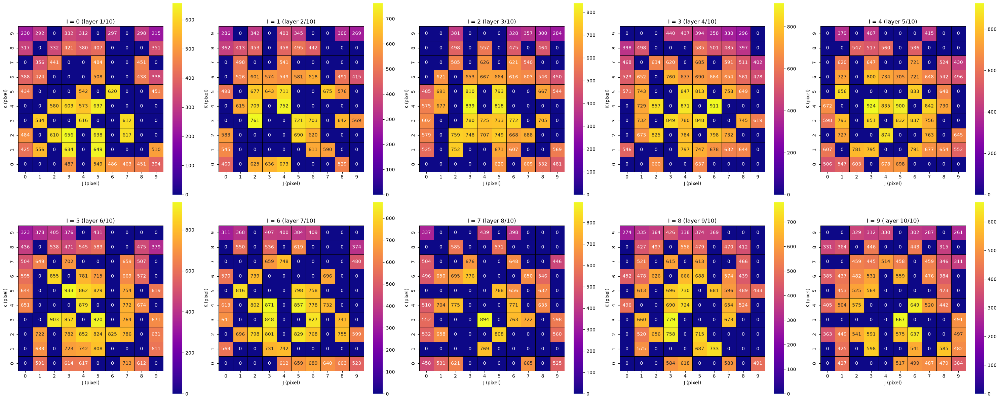

In [26]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.6 - Primary Positrons

In [27]:
prim_positrons = ds[ds["particle_type"] == "PrimaryPositrons"]

print("Primary Positrons dataset shape:", prim_positrons.shape)

prim_positrons = prim_positrons[cols]
print("Primary Positrons dataset shape after selecting columns:", prim_positrons.shape)
print("Selected columns:", prim_positrons.columns.tolist())

Primary Positrons dataset shape: (19636, 54)
Primary Positrons dataset shape after selecting columns: (19636, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [28]:
if "hits_sum" in prim_positrons.columns and "n_active" in prim_positrons.columns:
    discrepancies = prim_positrons[prim_positrons["n_active"] != prim_positrons["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        prim_positrons = prim_positrons.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in prim_positrons.columns and "n_active" in prim_positrons.columns:
    for i in range(prim_positrons.shape[0]):
        pixel_ijk = prim_positrons.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = prim_positrons.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [29]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in prim_positrons["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

In [30]:
tot_hitted = np.sum(hits_matrix)
print(f"Total number of hitted voxels: {tot_hitted}")

prim_positrons.head()

Total number of hitted voxels: 658795.0


,event_index,pixel_ijk,primary_e0_kev,n_active,hits_mean_active
300260,1,"[3,9,6];[4,9,6];[2,9,6];[6,9,7];[7,9,7];[1,9,6];[2,9,5];[4,9,7];[8,8,7];[7,8,6];[0,9,1];[1,9,3];[3,7,6];[9,8,7];[0,9,5];[6,9,8];[0,9,8];[5,8,7];[0,9,6];[3,9,7];[4,7,4];[0,8,0];[0,8,7];[2,7,2];[9,4,9];[4,6,3];[2,3,2];[3,8,7];[2,3,3];[5,7,7];[5,9,5];[0,8,6];[4,8,5];[9,2,7];[2,0,2];[3,8,6];[9,3,6];[6,8,3];[3,9,3];[3,4,2];[2,8,3];[2,8,5];[3,8,5];[9,8,8];[0,7,3];[2,7,0];[6,7,4];[2,4,2];[0,9,9];[5,9,3];[2,9,9];[1,8,6];[5,9,8];[5,7,5];[4,8,7];[3,7,2];[1,8,9];[2,5,2];[3,6,1];[2,2,2];[5,8,8];[2,5,3];[5,8,0];[1,5,3];[4,6,5];[3,8,3];[3,4,1];[4,6,7];[5,3,7];[0,7,2];[3,6,4];[2,8,6];[4,7,3];[9,7,4];[4,4,4];[4,5,4];[8,8,6];[7,8,5];[3,7,1];[0,8,9];[5,8,6]",3.231399e+07,81,1.0
300261,2,"[5,0,7];[5,1,7];[5,0,8];[4,1,7]",1.818261e+07,4,1.0
300262,4,"[8,4,8];[8,3,7];[9,4,7];[5,0,6];[9,6,8];[8,7,8];[8,2,8];[9,3,7];[8,5,8];[8,8,8];[7,2,8];[4,5,0];[8,4,9];[9,2,9];[9,3,6];[6,0,6];[9,3,8];[8,4,6];[7,8,5];[8,6,9]",2.340992e+07,20,1.0
300263,5,"[0,5,7];[2,6,8];[1,6,8];[1,5,8];[3,7,9];[1,4,7];[2,6,9];[3,6,9];[0,5,6];[0,4,5];[0,5,8];[4,4,6];[1,5,9];[1,5,6];[3,5,7];[1,4,6];[0,4,8];[0,2,7];[0,9,8];[2,6,7];[4,7,9];[3,6,8];[1,4,8];[2,8,8];[5,8,8];[2,4,7];[2,5,6];[0,2,8];[2,4,8];[0,4,4];[3,1,5];[3,3,9];[3,4,9];[1,1,7];[3,6,6];[1,4,5];[5,7,7];[3,7,7];[3,7,8];[0,3,4];[1,3,6];[3,5,9];[0,9,9];[1,1,8];[3,5,5];[2,4,6];[2,7,9];[1,8,3];[0,9,5];[3,4,6];[1,0,8];[1,4,9];[0,5,4]",1.593678e+07,53,1.0
300264,6,"[4,1,6];[3,1,6];[3,0,6];[5,2,6];[6,2,6];[2,0,5];[1,0,5];[0,0,6];[3,0,5];[0,0,5];[3,1,5];[2,1,5];[2,1,6];[4,1,5];[7,3,6];[7,2,6];[5,0,6];[3,3,6];[4,1,7];[0,0,8];[3,0,7];[4,1,3];[5,1,7];[3,4,5];[1,0,8];[9,3,6];[0,5,6];[1,2,8];[4,1,2];[1,4,6];[2,2,8];[3,1,4];[2,0,3];[2,3,4];[5,4,8];[2,0,4];[0,1,9];[3,0,8];[2,2,1];[1,1,4];[3,4,4];[4,6,8];[6,3,3];[1,0,2];[5,3,3];[1,2,6];[2,0,2];[4,3,6];[4,0,1];[3,1,8];[8,4,6];[1,4,5];[3,5,5];[2,8,6];[1,1,6];[5,3,5];[5,7,3];[5,0,7];[6,2,4];[1,3,6];[7,0,9];[7,6,5];[5,0,8];[3,1,2];[6,3,4];[4,2,0];[5,4,5];[8,1,7];[2,4,8];[7,1,2];[4,3,4];[6,1,5];[7,1,6];[6,0,6];[0,3,1];[8,3,4];[2,1,4];[2,3,6];[0,3,4];[9,1,8];[1,1,8];[0,1,6];[9,6,9];[9,6,8];[4,3,3];[5,9,8];[8,5,1];[1,3,5];[3,3,3];[2,3,5];[0,3,2];[7,2,8];[7,5,2];[4,4,4];[3,4,6];[7,0,3];[5,1,9];[6,1,9];[7,0,7];[5,5,8];[7,2,4];[1,2,5];[1,1,7];[0,0,2];[0,0,9];[1,2,4];[3,6,8];[3,5,8];[7,6,4];[3,3,9];[0,4,4];[0,2,7];[0,3,9];[8,0,6];[1,0,9];[1,2,3];[0,5,7];[4,4,6];[8,4,4];[6,5,5];[5,2,3];[5,0,5];[3,1,3];[3,2,4];[0,5,2];[3,5,7];[9,2,4];[4,2,8];[6,5,8];[0,1,7]",2.350056e+07,130,1.0


Plot the detector hitted-subcubes in 2D layer by layer:

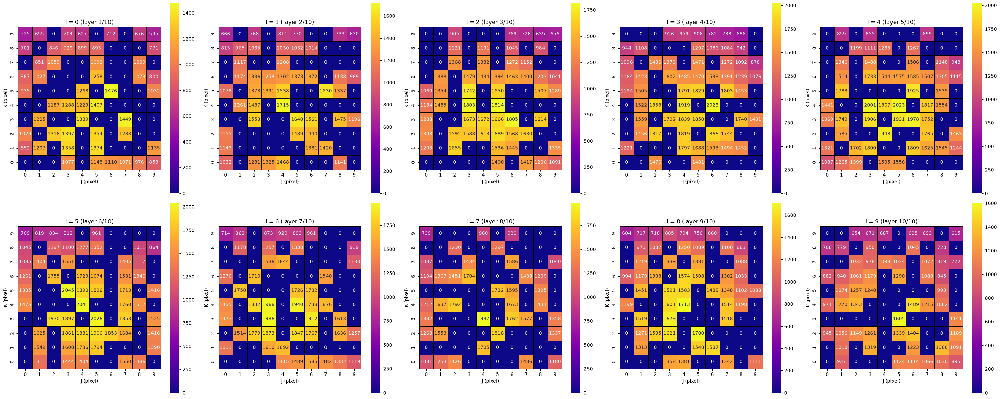

In [31]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.7 - Primary Protons

In [32]:
prim_protons = ds[ds["particle_type"] == "PrimaryProtons"]

print("Primary Protons dataset shape:", prim_protons.shape)

prim_protons = prim_protons[cols]
print("Primary Protons dataset shape after selecting columns:", prim_protons.shape)
print("Selected columns:", prim_protons.columns.tolist())

Primary Protons dataset shape: (18461, 54)
Primary Protons dataset shape after selecting columns: (18461, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [33]:
if "hits_sum" in prim_protons.columns and "n_active" in prim_protons.columns:
    discrepancies = prim_protons[prim_protons["n_active"] != prim_protons["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        prim_protons = prim_protons.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in prim_protons.columns and "n_active" in prim_protons.columns:
    for i in range(prim_protons.shape[0]):
        pixel_ijk = prim_protons.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = prim_protons.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [34]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in prim_protons["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

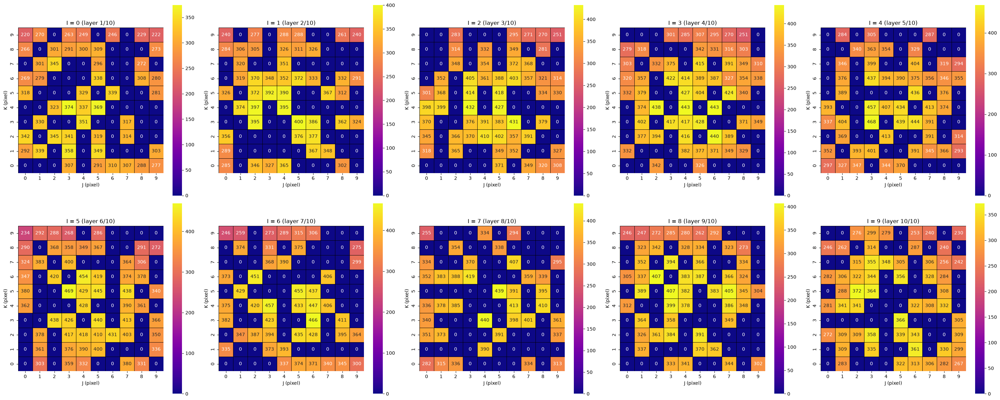

In [35]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.8 - Secondary Electrons

In [36]:
sec_electrons = ds[ds["particle_type"] == "SecondaryElectrons"]

print("Secondary Electrons dataset shape:", sec_electrons.shape)

sec_electrons = sec_electrons[cols]
print("Secondary Electrons dataset shape after selecting columns:", sec_electrons.shape)
print("Selected columns:", sec_electrons.columns.tolist())

Secondary Electrons dataset shape: (8730, 54)
Secondary Electrons dataset shape after selecting columns: (8730, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [37]:
if "hits_sum" in sec_electrons.columns and "n_active" in sec_electrons.columns:
    discrepancies = sec_electrons[sec_electrons["n_active"] != sec_electrons["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        sec_electrons = sec_electrons.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in sec_electrons.columns and "n_active" in sec_electrons.columns:
    for i in range(sec_electrons.shape[0]):
        pixel_ijk = sec_electrons.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = sec_electrons.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [38]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in sec_electrons["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

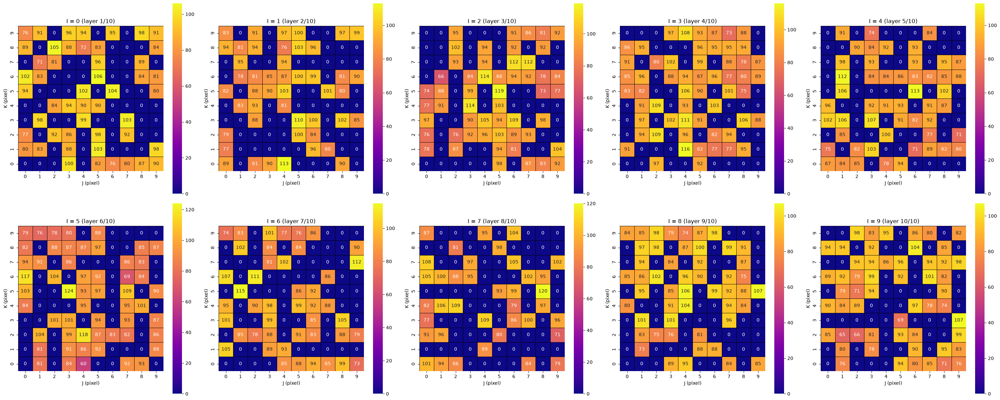

In [39]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.9 - Secondary Positrons 

In [40]:
sec_positrons = ds[ds["particle_type"] == "SecondaryPositrons"]

print("Secondary Positrons dataset shape:", sec_positrons.shape)

sec_positrons = sec_positrons[cols]
print("Secondary Positrons dataset shape after selecting columns:", sec_positrons.shape)
print("Selected columns:", sec_positrons.columns.tolist())

Secondary Positrons dataset shape: (29089, 54)
Secondary Positrons dataset shape after selecting columns: (29089, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [41]:
if "hits_sum" in sec_positrons.columns and "n_active" in sec_positrons.columns:
    discrepancies = sec_positrons[sec_positrons["n_active"] != sec_positrons["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        sec_positrons = sec_positrons.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in sec_positrons.columns and "n_active" in sec_positrons.columns:
    for i in range(sec_positrons.shape[0]):
        pixel_ijk = sec_positrons.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = sec_positrons.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [42]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in sec_positrons["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

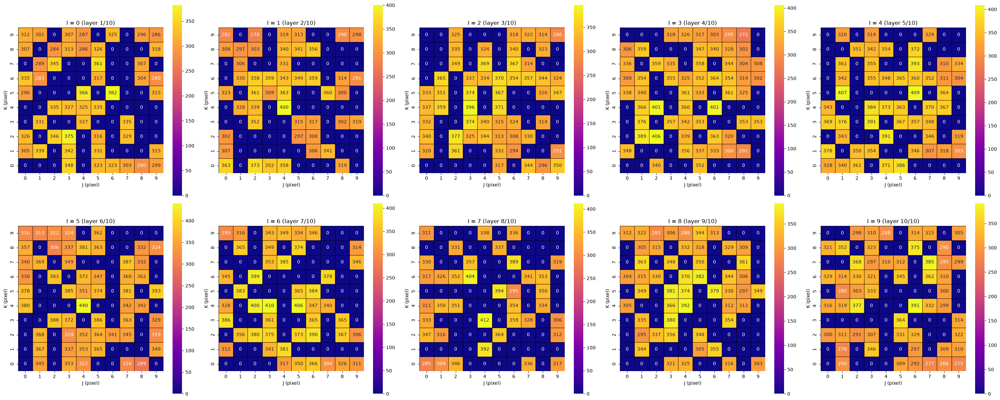

In [43]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.10 - Secondary Protons (Downward)

In [44]:
sec_protons_dw = ds[ds["particle_type"] == "SecondaryProtonsDownward"]
print("Secondary Protons (Downward) dataset shape:", sec_protons_dw.shape)

sec_protons_dw = sec_protons_dw[cols]
print("Secondary Protons (Downward) dataset shape after selecting columns:", sec_protons_dw.shape)
print("Selected columns:", sec_protons_dw.columns.tolist())

Secondary Protons (Downward) dataset shape: (11060, 54)
Secondary Protons (Downward) dataset shape after selecting columns: (11060, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [45]:
if "hits_sum" in sec_protons_dw.columns and "n_active" in sec_protons_dw.columns:
    discrepancies = sec_protons_dw[sec_protons_dw["n_active"] != sec_protons_dw["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        sec_protons_dw = sec_protons_dw.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in sec_protons_dw.columns and "n_active" in sec_protons_dw.columns:
    for i in range(sec_protons_dw.shape[0]):
        pixel_ijk = sec_protons_dw.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = sec_protons_dw.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [46]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in sec_protons_dw["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

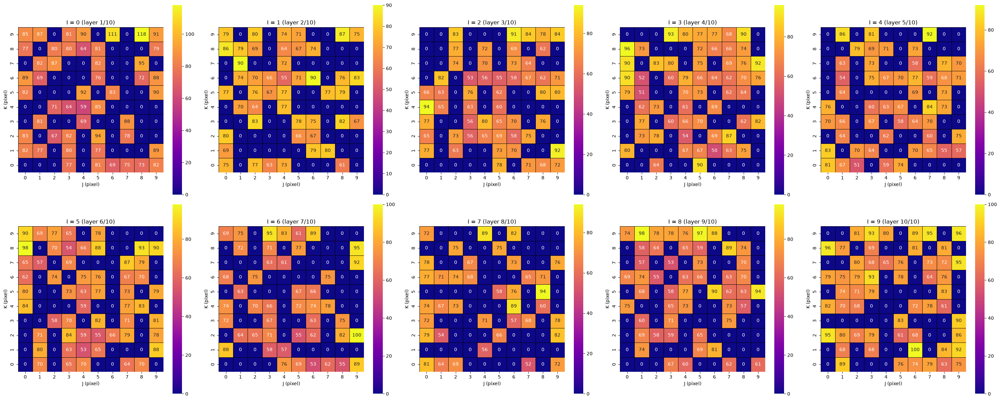

In [47]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.11 - Secondary Protons (Upward)

In [48]:
sec_protons_up = ds[ds["particle_type"] == "SecondaryProtonsUpward"]

print("Secondary Protons Upward dataset shape:", sec_protons_up.shape)

sec_protons_up = sec_protons_up[cols]
print("Secondary Protons Upward dataset shape after selecting columns:", sec_protons_up.shape)
print("Selected columns:", sec_protons_up.columns.tolist())

Secondary Protons Upward dataset shape: (11901, 54)
Secondary Protons Upward dataset shape after selecting columns: (11901, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [49]:
if "hits_sum" in sec_protons_up.columns and "n_active" in sec_protons_up.columns:
    discrepancies = sec_protons_up[sec_protons_up["n_active"] != sec_protons_up["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        sec_protons_up = sec_protons_up.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in sec_protons_up.columns and "n_active" in sec_protons_up.columns:
    for i in range(sec_protons_up.shape[0]):
        pixel_ijk = sec_protons_up.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = sec_protons_up.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")

Discrepnacies between n_active and hits_sum: 0
Drop hits_sum column since it is redundant with n_active
No discrepancies!


Do a 3D plot of the hitted sub-cubes:

In [50]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in sec_protons_up["pixel_ijk"]:
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

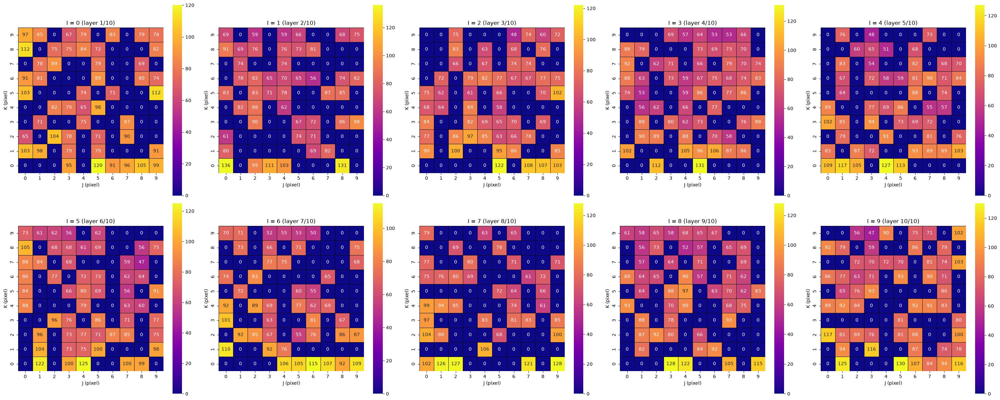

In [51]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

## 1.12 - TGF

In [52]:
tgf = ds[ds["particle_type"] == "TGF"]
print("Albedo Photons dataset shape:", tgf.shape)

tgf = tgf[cols]
print("Albedo Photons dataset shape after selecting columns:", tgf.shape)
print("Selected columns:", tgf.columns.tolist())

Albedo Photons dataset shape: (928000, 54)
Albedo Photons dataset shape after selecting columns: (928000, 6)
Selected columns: ['event_index', 'pixel_ijk', 'primary_e0_kev', 'n_active', 'hits_sum', 'hits_mean_active']


Check if the `n_active` and `hits_sum` are the same value and if it is consistend with the dimension of `pixel_ijk`: 

In [53]:
if "hits_sum" in albedo.columns and "n_active" in albedo.columns:
    discrepancies = albedo[albedo["n_active"] != albedo["hits_sum"]]
    print("Discrepnacies between n_active and hits_sum:", discrepancies.shape[0])

    if discrepancies.shape[0] == 0:
        print("Drop hits_sum column since it is redundant with n_active")
        albedo = albedo.drop(columns=["hits_sum"])

# check consisntency between n_active and dimension of pixel_ijk
if "pixel_ijk" in albedo.columns and "n_active" in albedo.columns:
    for i in range(albedo.shape[0]):
        pixel_ijk = albedo.iloc[i]["pixel_ijk"]
        number_of_pixels = len(pixel_ijk.split(";")) if isinstance(pixel_ijk, str) else 0
        n_active = albedo.iloc[i]["n_active"]
        if number_of_pixels != n_active:
            print(f"Discrepancy at index {i}: n_active = {n_active}, number of pixels in pixel_ijk = {number_of_pixels}")

print("No discrepancies!")
print("tgf dataset shape:", tgf.shape)

No discrepancies!
tgf dataset shape: (928000, 6)


Do a 3D plot of the hitted sub-cubes:

In [54]:
hits_matrix = np.zeros((DIM_CUBE, DIM_CUBE, DIM_CUBE))

for pixels_ijk in tgf["pixel_ijk"]: 
    for pixel_str in pixels_ijk.split(";"):
        i, j, k = pixel_conversion(pixel_str)
        hits_matrix[i, j, k] += 1

# Normalization of the hits matrix to have values between 0 and 1
# max_val = np.max(hits_matrix)
# if max_val > 0:
#     hits_matrix /= max_val

fig = create_detection_cube(
    hits_matrix,
    gap=0.08,
    colorscale="Plasma",   # Turbo or Plasma
    opacity=0.9,
    min_hitted=0.0      
)
fig.show()

Plot the detector hitted-subcubes in 2D layer by layer:

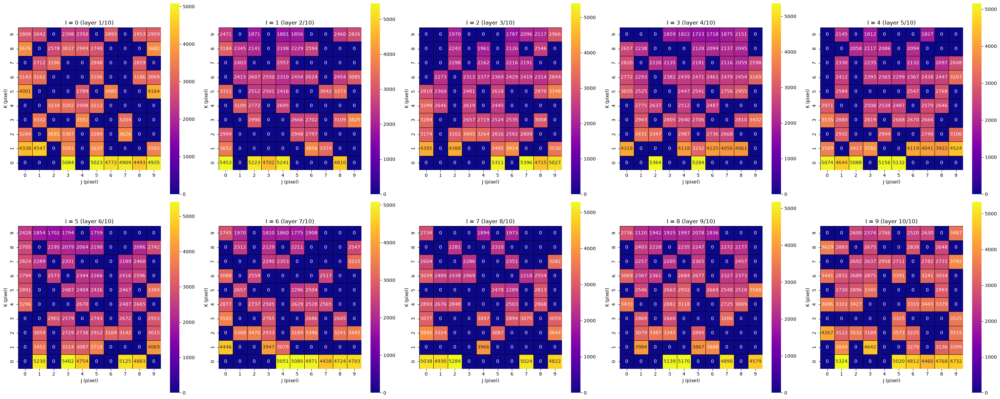

In [55]:
plot_detector_layes(
    hits_matrix,
    colorscale="plasma", 
    min_hitted=0.0
)

# 2 - Comparison of hits-based metrics

In this section the hits metrics are compared.

In [56]:
sources = {
    "Albedo Photons": albedo,
    "Atmospheric Neutrons": atm_neutrons,
    "Cosmic Photons": cosmic_pht,
    "Primary Alphas": prim_alphas,
    "Primary Electrons": prim_electrons,
    "Primary Positrons": prim_positrons,
    "Primary Protons": prim_protons,
    "Secondary Electrons": sec_electrons,
    "Secondary Positrons": sec_positrons,
    "Secondary Protons Downward": sec_protons_dw,
    "Secondary Protons Upward": sec_protons_up,
    "TGF": tgf
}


In [57]:
rows = []

for source, df in sources.items():
    hits = pd.to_numeric(df["n_active"], errors="coerce").dropna()

    k_values = []
    j_values = []
    i_values = []
    for pixel_ijk in df["pixel_ijk"].dropna():
        for pixel_str in pixel_ijk.split(";"):
            i, j, k = pixel_conversion(pixel_str)
            i_values.append(i)
            j_values.append(j)
            k_values.append(k)

    rows.append({
        "Source": source,
        "Num. Events": len(hits),
        "Total Hits": hits.sum(),
        "Mean Hits": hits.mean(),
        "Std. Hits": hits.std(),
        "Median Hits": hits.median(),
        "Min Hits": hits.min(),
        "Max Hits": hits.max(),
        "Barycenter I": np.mean(i_values).round(2),
        "Barycenter J": np.mean(j_values).round(2),
        "Barycenter K": np.mean(k_values).round(2),
    })

hits_stats_df = pd.DataFrame(rows).set_index("Source")

hits_stats_df

,Num. Events,Total Hits,Mean Hits,Std. Hits,Median Hits,Min Hits,Max Hits,Barycenter I,Barycenter J,Barycenter K
Source,,,,,,,,,,
Albedo Photons,86862,138423,1.593597,2.010771,1.0,1,86,4.49,4.42,3.89
Atmospheric Neutrons,9962,21188,2.126882,2.874332,1.0,1,123,4.45,4.45,4.45
Cosmic Photons,152860,170910,1.118082,0.410773,1.0,1,31,4.49,4.43,5.16
Primary Alphas,11677,163680,14.017299,30.436139,5.0,1,371,4.47,4.36,4.44
Primary Electrons,8537,294029,34.441724,43.002162,16.0,1,293,4.46,4.38,4.25
Primary Positrons,19636,658795,33.550367,43.398167,14.0,1,358,4.48,4.40,4.24
Primary Protons,18461,173830,9.416066,18.916254,5.0,1,280,4.48,4.38,4.49
Secondary Electrons,8730,45335,5.193013,7.485731,2.0,1,155,4.45,4.39,4.66
Secondary Positrons,29089,168679,5.798721,7.363655,3.0,1,132,4.48,4.36,4.61


# Conclusions

As we can see from the plots and from the metrics analysed in the last section, the *hits* information alone **cannot be used** as a good discriminator of background source. 

For example: the Albedo Photons that come from earth atmosphere (below the detector) have a non-negligible high number of activations in the top layers of the detector (K~=9).

Neither the number of hits nor the barycenter is a reliable indicator, as their values remain similar across the different sources.